# Uçtan Uca Yapay Zeka Projesi: Veriden Tahmine

Bu defterde oyun alanındaki bir veri seti üzerinden problem tanımı, veri temizleme, keşifçi veri analizi, model eğitimi, değerlendirme ve mini tahmin uygulaması adımları sırasıyla uygulanmıştır.

**Araçlar:** Python, Google Colab, Pandas, NumPy, Matplotlib, scikit-learn

## Aşama 1: Problem Tanımı ve Proje Planı

| Alan | Açıklama |
| :--- | :--- |
| **Seçilen Alan** | Oyun (Video Oyunları) |
| **Problem Cümlesi** | Bir oyunun türü, platformu, geliştirme ölçeği, çıkış yılı, fiyatı (USD), ortalama oynanış süresi, çok oyunculu desteği, erken erişim durumu ve DLC sayısı bilgilerinden yola çıkarak kullanıcı puanını (0-100) tahmin et. |
| **Özellikler (X)** | `tur`, `platform`, `gelistirme_olcegi`, `cikis_yili`, `fiyat_usd`, `ortalama_oynanis_saati`, `cok_oyunculu`, `erken_erisim`, `dlc_sayisi` |
| **Hedef Değişken (y)** | `kullanici_puani` |
| **Problem Türü** | Regresyon (hedef değişken sayısal bir puan olduğu için) |

**Gerekçe (Bu Problem Neden Önemli?):**
Bir oyun geliştirilirken satış fiyatının ne olacağı, erken erişimle çıkıp çıkmayacağı, çok oyunculu mod eklenip eklenmeyeceği veya kaç adet ek paket (DLC) hazırlanacağı doğrudan oyuncu tepkisini etkiler. Özellikle küçük ve orta ölçekli oyun stüdyoları sınırlı bütçelerini doğru yönetebilmek için bu özelliklerin oyuncu memnuniyetine nasıl yansıdığını önceden görmek ister. Benzer oyunların geçmiş verilerine bakarak kullanıcı puanını tahmin eden bir model, geliştiricilere çıkış öncesinde fiyat ve içerik dengesini ayarlama konusunda fikir verirken; oyunculara ve yayıncılara da bir oyunun beklenen kalitesi hakkında ön değerlendirme imkanı sunar.

## Aşama 2: Veri Toplama ve Hazırlama

İlk olarak gerekli kütüphaneleri ekleyip `oyun_verileri.csv` dosyasını `pd.read_csv` ile okuyoruz ve özellik (`X`) ile hedef (`y`) sütunlarını inceliyoruz.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

github_csv_url = "https://raw.githubusercontent.com/sefakesen/veriden-tahmine-oyun-projesi/main/data/oyun_verileri.csv"

if os.path.exists("oyun_verileri.csv"):
    dosya_yolu = "oyun_verileri.csv"
elif os.path.exists("data/oyun_verileri.csv"):
    dosya_yolu = "data/oyun_verileri.csv"
else:
    dosya_yolu = github_csv_url

df = pd.read_csv(dosya_yolu)
print("Ham veri boyutu (shape):", df.shape)

ozellik_sutunlari = [
    "tur", "platform", "gelistirme_olcegi", "cikis_yili",
    "fiyat_usd", "ortalama_oynanis_saati", "cok_oyunculu", "erken_erisim", "dlc_sayisi"
]
hedef_sutun = "kullanici_puani"

print("Özellik sütunları (X):", ozellik_sutunlari)
print("Hedef sütun (y):", hedef_sutun)
df.head()

Ham veri boyutu (shape): (96, 11)
Özellik sütunları (X): ['tur', 'platform', 'gelistirme_olcegi', 'cikis_yili', 'fiyat_usd', 'ortalama_oynanis_saati', 'cok_oyunculu', 'erken_erisim', 'dlc_sayisi']
Hedef sütun (y): kullanici_puani


,oyun_adi,tur,platform,gelistirme_olcegi,cikis_yili,fiyat_usd,ortalama_oynanis_saati,cok_oyunculu,erken_erisim,dlc_sayisi,kullanici_puani
0,PUBG Mobile,Aksiyon,Mobil,AAA,2018,0.00,32.0,Evet,Hayir,0.0,70.0
1,Tetris Effect,Bulmaca,Coklu Platform,Orta Olcekli,2018,39.99,15.0,Evet,Hayir,0.0,90.0
2,ARK: Survival Evolved,Simulasyon,Coklu Platform,Orta Olcekli,2017,29.99,52.0,Evet,Evet,5.0,76.0
3,Elden Ring,RPG,Coklu Platform,AAA,2022,59.99,68.0,Evet,Hayir,1.0,90.0
4,Baba Is You,Bulmaca,Coklu Platform,Indie,2019,14.99,20.0,Hayir,Hayir,0.0,90.0


### Veri Sözlüğü

Veri setinde toplam 11 sütun yer alıyor. `oyun_adi` sütunu yalnızca oyunları ayırt etmek için tutuluyor ve modele verilmiyor. Diğer 9 sütun özellik (`X`), `kullanici_puani` ise hedef (`y`) sütunudur.

| Sütun Adı | Tip | Anlamı |
| :--- | :--- | :--- |
| `oyun_adi` | Kategorik (Metin) | Oyunun adı (tanımlayıcı sütun). |
| `tur` | Kategorik | Oyunun ana türü (`Aksiyon`, `RPG`, `Strateji`, `Simulasyon`, `Bulmaca`, `Spor`). |
| `platform` | Kategorik | Oyunun yayınlandığı platform (`PC`, `Konsol`, `Mobil`, `Coklu Platform`). |
| `gelistirme_olcegi` | Kategorik | Geliştirici stüdyo ve bütçe ölçeği (`Indie`, `Orta Olcekli`, `AAA`). |
| `cikis_yili` | Sayısal | Oyunun çıkış yılı (`2009`-`2024`). |
| `fiyat_usd` | Sayısal | Oyunun satış fiyatı (USD). `0` değeri ücretsiz oyunları gösterir. |
| `ortalama_oynanis_saati` | Sayısal | Oyuncuların oyunu ortalama oynama süresi (saat). |
| `cok_oyunculu` | Kategorik | Çok oyunculu mod desteği (`Evet` / `Hayir`). |
| `erken_erisim` | Kategorik | Erken erişim sürecinden geçip geçmediği (`Evet` / `Hayir`). |
| `dlc_sayisi` | Sayısal | Oyun için yayınlanan ek paket (DLC) sayısı. |
| `kullanici_puani` | Sayısal | **Hedef değişken (y):** 0-100 arası kullanıcı memnuniyet puanı. |

In [2]:
# Eksik ve hatalı değerlerin tespiti
print("--- Sütunlardaki eksik değer sayıları (isnull) ---")
print(df.isnull().sum())

print("\nTekrar eden satır sayısı:", df.duplicated().sum())
print("Negatif fiyat sayısı:", (df["fiyat_usd"] < 0).sum())
print("Hatalı çıkış yılı (> 2025):", (df["cikis_yili"] > 2025).sum())
print("0-100 dışı kullanıcı puanı:", ((df["kullanici_puani"] < 0) | (df["kullanici_puani"] > 100)).sum())

--- Sütunlardaki eksik değer sayıları (isnull) ---
oyun_adi                  0
tur                       0
platform                  2
gelistirme_olcegi         0
cikis_yili                0
fiyat_usd                 2
ortalama_oynanis_saati    2
cok_oyunculu              0
erken_erisim              0
dlc_sayisi                2
kullanici_puani           2
dtype: int64

Tekrar eden satır sayısı: 2
Negatif fiyat sayısı: 1
Hatalı çıkış yılı (> 2025): 1
0-100 dışı kullanıcı puanı: 1


In [3]:
# 1. Tekrar eden satırları kaldır
df_temiz = df.drop_duplicates().copy()

# 2. Hedef değişken boş veya 0-100 dışındaysa satırı çıkar (dropna)
df_temiz = df_temiz.dropna(subset=["kullanici_puani"])
df_temiz = df_temiz[(df_temiz["kullanici_puani"] >= 0) & (df_temiz["kullanici_puani"] <= 100)]

# 3. Hatalı fiyat ve çıkış yılı kayıtlarını temizle (boş olanlar fillna ile doldurulacak)
df_temiz = df_temiz[df_temiz["fiyat_usd"].isna() | (df_temiz["fiyat_usd"] >= 0)]
df_temiz = df_temiz[(df_temiz["cikis_yili"] >= 2000) & (df_temiz["cikis_yili"] <= 2025)]

# 4. Özelliklerdeki eksik değerleri mod ve medyan ile doldur (fillna)
df_temiz["platform"] = df_temiz["platform"].fillna(df_temiz["platform"].mode()[0])

for sutun in ["fiyat_usd", "ortalama_oynanis_saati", "dlc_sayisi"]:
    df_temiz[sutun] = df_temiz[sutun].fillna(df_temiz[sutun].median())

df_temiz["dlc_sayisi"] = df_temiz["dlc_sayisi"].round().astype(int)
df_temiz = df_temiz.reset_index(drop=True)

print("Temizleme öncesi satır:", len(df))
print("Temizleme sonrası satır:", len(df_temiz))
print("Kalan toplam eksik değer:", df_temiz.isnull().sum().sum())

Temizleme öncesi satır: 96
Temizleme sonrası satır: 89
Kalan toplam eksik değer: 0


**Temizleme Özeti:** Tekrar eden 2 satır `drop_duplicates` ile silindi. Hedef sütunu (`kullanici_puani`) boş olan 2 satır ve 0-100 aralığı dışındaki 1 hatalı kayıt (`115.0`) `dropna` ve aralık filtresiyle çıkarıldı. Negatif fiyat (`-19.99`) ve gelecekten hatalı çıkış yılı (`2099`) içeren 2 satır temizlendi. Özellik sütunlarındaki kalan eksikler ise `fillna` kullanılarak kategorik sütunda mod, sayısal sütunlarda medyan ile dolduruldu ve toplam **89 temiz satır** elde edildi.

## Aşama 3: Keşifçi Veri Analizi (EDA) ve Görselleştirme

Temiz veri setini `shape`, `head()`, `describe()`, `groupby` ve `value_counts` kullanarak inceleyelim, ardından en az 2 etiketli Matplotlib grafiği çizelim.

In [4]:
print("Temiz veri boyutu (shape):", df_temiz.shape)
display(df_temiz.head())
display(df_temiz.describe().round(2))

print("--- Oyun Türlerinin Dağılımı (value_counts) ---")
print(df_temiz["tur"].value_counts())

print("\n--- Geliştirme Ölçeğine Göre Puan Ortalamaları (groupby) ---")
print(df_temiz.groupby("gelistirme_olcegi")["kullanici_puani"].agg(["count", "mean", "median"]).round(1))

print("\n--- Türe Göre Ortalama Puan ve Oynanış Süresi (groupby) ---")
print(df_temiz.groupby("tur")[["kullanici_puani", "ortalama_oynanis_saati", "fiyat_usd"]].mean().round(1))

Temiz veri boyutu (shape): (89, 11)


,oyun_adi,tur,platform,gelistirme_olcegi,cikis_yili,fiyat_usd,ortalama_oynanis_saati,cok_oyunculu,erken_erisim,dlc_sayisi,kullanici_puani
0,PUBG Mobile,Aksiyon,Mobil,AAA,2018,0.00,32.0,Evet,Hayir,0,70.0
1,Tetris Effect,Bulmaca,Coklu Platform,Orta Olcekli,2018,39.99,15.0,Evet,Hayir,0,90.0
2,ARK: Survival Evolved,Simulasyon,Coklu Platform,Orta Olcekli,2017,29.99,52.0,Evet,Evet,5,76.0
3,Elden Ring,RPG,Coklu Platform,AAA,2022,59.99,68.0,Evet,Hayir,1,90.0
4,Baba Is You,Bulmaca,Coklu Platform,Indie,2019,14.99,20.0,Hayir,Hayir,0,90.0


,cikis_yili,fiyat_usd,ortalama_oynanis_saati,dlc_sayisi,kullanici_puani
count,89.00,89.00,89.00,89.00,89.00
mean,2018.87,36.37,37.87,1.30,78.33
std,3.46,23.90,22.98,2.37,17.82
min,2009.00,0.00,3.50,0.00,28.00
25%,2017.00,14.99,18.00,0.00,74.00
50%,2019.00,39.99,34.00,0.00,86.00
75%,2022.00,59.99,52.00,2.00,91.00
max,2024.00,69.99,98.00,12.00,95.00


--- Oyun Türlerinin Dağılımı (value_counts) ---
tur
Aksiyon       32
RPG           14
Simulasyon    13
Strateji      11
Spor          10
Bulmaca        9
Name: count, dtype: int64

--- Geliştirme Ölçeğine Göre Puan Ortalamaları (groupby) ---
                   count  mean  median
gelistirme_olcegi                     
AAA                   47  73.4    78.0
Indie                 24  90.1    91.0
Orta Olcekli          18  75.3    83.0

--- Türe Göre Ortalama Puan ve Oynanış Süresi (groupby) ---
            kullanici_puani  ortalama_oynanis_saati  fiyat_usd
tur                                                           
Aksiyon                76.2                    30.1       35.3
Bulmaca                86.2                    13.8       19.3
RPG                    78.8                    50.5       47.5
Simulasyon             84.9                    53.2       33.1
Spor                   64.7                    28.8       52.0
Strateji               81.9                    54.2       29.

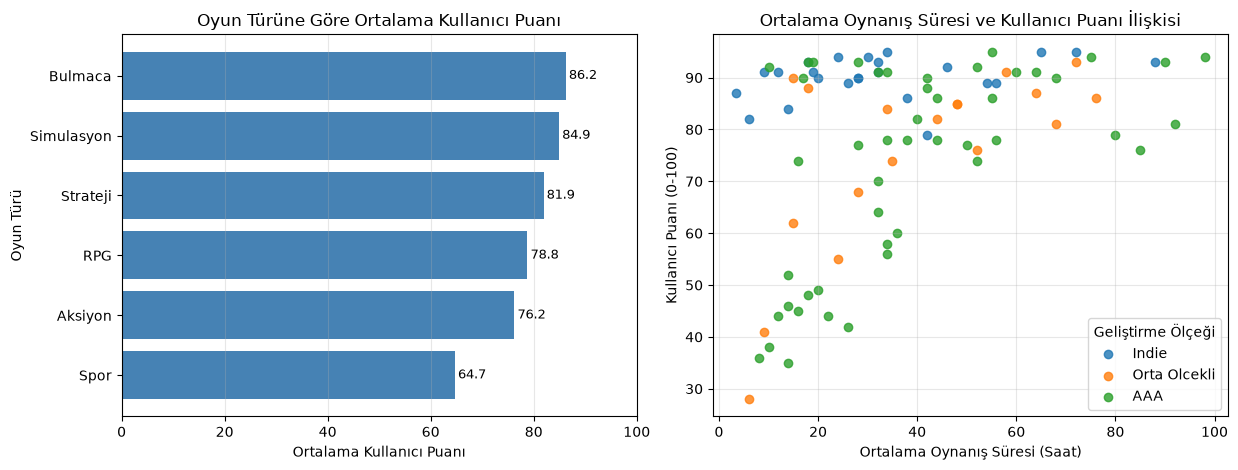

In [5]:
plt.figure(figsize=(12.5, 4.8))

# Grafik 1 (Bar): Oyun türüne göre ortalama kullanıcı puanı
plt.subplot(1, 2, 1)
tur_ort = df_temiz.groupby("tur")["kullanici_puani"].mean().sort_values()
plt.barh(tur_ort.index, tur_ort.values, color="steelblue")
for i, deger in enumerate(tur_ort.values):
    plt.text(deger + 0.6, i, f"{deger:.1f}", va="center", fontsize=9)
plt.title("Oyun Türüne Göre Ortalama Kullanıcı Puanı")
plt.xlabel("Ortalama Kullanıcı Puanı")
plt.ylabel("Oyun Türü")
plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)

# Grafik 2 (Scatter): Ortalama oynanış süresi vs kullanıcı puanı
plt.subplot(1, 2, 2)
renkler = {"Indie": "tab:blue", "Orta Olcekli": "tab:orange", "AAA": "tab:green"}
for olcek, renk in renkler.items():
    alt = df_temiz[df_temiz["gelistirme_olcegi"] == olcek]
    plt.scatter(alt["ortalama_oynanis_saati"], alt["kullanici_puani"], label=olcek, color=renk, alpha=0.8)

plt.title("Ortalama Oynanış Süresi ve Kullanıcı Puanı İlişkisi")
plt.xlabel("Ortalama Oynanış Süresi (Saat)")
plt.ylabel("Kullanıcı Puanı (0-100)")
plt.legend(title="Geliştirme Ölçeği")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Keşif Bulguları

- **Hangi özellikler belirleyici?** Veri setinde kullanıcı puanı üzerindeki farkı en belirgin şekilde açıklayan özellikler `ortalama_oynanis_saati`, `gelistirme_olcegi` ve `tur` değişkenleridir.
- **Oynanış süresi etkisi:** Saçılım grafiğinde ortalama oynanış süresi `30` saatin üzerine çıkan oyunların büyük çoğunluğunun `75` ve üzeri puan aldığı, `15` saatin altındaki yüksek fiyatlı oyunlarda ise düşük puan riskinin arttığı görülüyor.
- **Geliştirme ölçeği farkı:** `Indie` oyunların ortalama kullanıcı puanı `90.1` (medyan `91.0`) ile oldukça yüksekken, `AAA` oyunların ortalaması `73.4` düzeyinde kalıyor; bunda yüksek fiyatlı veya tartışmalı çıkış yapmış büyük yapımların puanı aşağı çekmesi etkili.
- **Türlere göre dağılım ve puanlar:** Veri setinde en sık `Aksiyon` (`32` oyun) türü yer alırken, ortalama puanda `Bulmaca` (`86.2`), `Simulasyon` (`84.9`) ve `Strateji` (`81.9`) önde, `Spor` (`64.7`) ise en geride yer alıyor.

## Aşama 4: Model Kurma ve Eğitme

Kategorik değişkenleri `pd.get_dummies` ile sayısal sütunlara çevirip `X` ve `y` dizilerini ayırıyoruz. Ardından veriyi %75 eğitim, %25 test olarak bölüp `LinearRegression` ve karşılaştırma için `DecisionTreeRegressor` modellerini eğitiyoruz.

**Model Seçim Gerekçesi:**
Hedef değişkenimiz (`kullanici_puani`) sürekli bir sayı olduğu için temel regresyon algoritmalarından `LinearRegression` seçilmiştir. Doğrusal olmayan kuralların performansını kıyaslamak amacıyla ikinci bir model olarak karar ağacı tabanlı `DecisionTreeRegressor` da aynı veri üzerinde eğitilmiştir. Küçük veri setinde aşırı ezberlemeyi önlemek için karar ağacında derinlik sınırı (`max_depth=3`, `min_samples_leaf=5`) uygulanmıştır.

In [6]:
kategorik_sutunlar = ["tur", "platform", "gelistirme_olcegi", "cok_oyunculu", "erken_erisim"]

X = df_temiz[ozellik_sutunlari]
y = df_temiz["kullanici_puani"]

X_hazir = pd.get_dummies(X, columns=kategorik_sutunlar, drop_first=True, dtype=int)
model_sutunlari = list(X_hazir.columns)

X_train, X_test, y_train, y_test = train_test_split(X_hazir, y, test_size=0.25, random_state=42)

print("Eğitim X boyutu:", X_train.shape, "| Eğitim y boyutu:", y_train.shape)
print("Test X boyutu  :", X_test.shape, " | Test y boyutu  :", y_test.shape)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

dt_model = DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=42)
dt_model.fit(X_train, y_train)

print("Modeller eğitildi.")

Eğitim X boyutu: (66, 16) | Eğitim y boyutu: (66,)
Test X boyutu  : (23, 16)  | Test y boyutu  : (23,)
Modeller eğitildi.


## Aşama 5: Tahmin ve Değerlendirme

Test verisi üzerinde `model.predict` ile tahmin üretip `model.score` ($R^2$), MAE ve RMSE skorlarını ölçüyoruz; ardından en az 3 yeni örnek için tahmin tablosu oluşturuyoruz.

,Model,Eğitim R2 (score),Test R2 (score),Test MAE,Test RMSE
0,LinearRegression,0.555,0.524,9.65,13.00
1,DecisionTreeRegressor,0.518,0.453,9.49,13.93


Seçilen ana model: LinearRegression


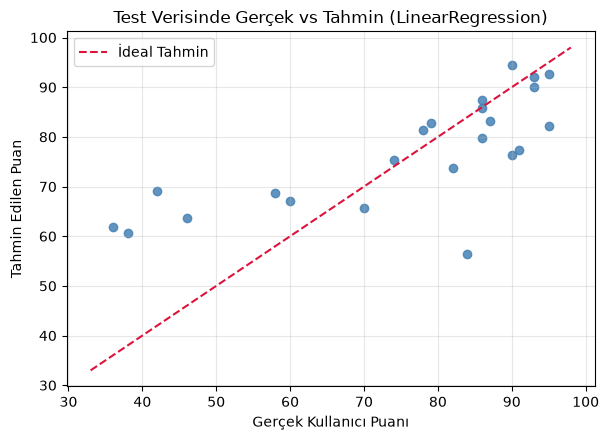

In [7]:
lr_tahmin = lr_model.predict(X_test)
dt_tahmin = dt_model.predict(X_test)

sonuc_df = pd.DataFrame([
    {
        "Model": "LinearRegression",
        "Eğitim R2 (score)": round(lr_model.score(X_train, y_train), 3),
        "Test R2 (score)": round(lr_model.score(X_test, y_test), 3),
        "Test MAE": round(mean_absolute_error(y_test, lr_tahmin), 2),
        "Test RMSE": round(float(np.sqrt(mean_squared_error(y_test, lr_tahmin))), 2),
    },
    {
        "Model": "DecisionTreeRegressor",
        "Eğitim R2 (score)": round(dt_model.score(X_train, y_train), 3),
        "Test R2 (score)": round(dt_model.score(X_test, y_test), 3),
        "Test MAE": round(mean_absolute_error(y_test, dt_tahmin), 2),
        "Test RMSE": round(float(np.sqrt(mean_squared_error(y_test, dt_tahmin))), 2),
    },
])
display(sonuc_df)

secilen_model = lr_model if lr_model.score(X_test, y_test) >= dt_model.score(X_test, y_test) else dt_model
secilen_model_adi = "LinearRegression" if secilen_model is lr_model else "DecisionTreeRegressor"
print("Seçilen ana model:", secilen_model_adi)

# Gerçek vs Tahmin grafiği
plt.figure(figsize=(6.2, 4.5))
secilen_tahmin = secilen_model.predict(X_test)
plt.scatter(y_test, secilen_tahmin, color="steelblue", alpha=0.85)
alt_s = min(y_test.min(), secilen_tahmin.min()) - 3
ust_s = max(y_test.max(), secilen_tahmin.max()) + 3
plt.plot([alt_s, ust_s], [alt_s, ust_s], color="crimson", linestyle="--", label="İdeal Tahmin")
plt.title(f"Test Verisinde Gerçek vs Tahmin ({secilen_model_adi})")
plt.xlabel("Gerçek Kullanıcı Puanı")
plt.ylabel("Tahmin Edilen Puan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# En az 3 yeni örnek için tahmin tablosu (girdi -> tahmin)
ornek_oyunlar = pd.DataFrame([
    {"oyun": "Örnek 1 (Indie RPG)", "tur": "RPG", "platform": "PC", "gelistirme_olcegi": "Indie", "cikis_yili": 2023, "fiyat_usd": 24.99, "ortalama_oynanis_saati": 48.0, "cok_oyunculu": "Hayir", "erken_erisim": "Evet", "dlc_sayisi": 0},
    {"oyun": "Örnek 2 (AAA Çoklu Oyunculu)", "tur": "Aksiyon", "platform": "Coklu Platform", "gelistirme_olcegi": "AAA", "cikis_yili": 2024, "fiyat_usd": 69.99, "ortalama_oynanis_saati": 14.0, "cok_oyunculu": "Evet", "erken_erisim": "Hayir", "dlc_sayisi": 2},
    {"oyun": "Örnek 3 (Ücretsiz Mobil Spor)", "tur": "Spor", "platform": "Mobil", "gelistirme_olcegi": "Orta Olcekli", "cikis_yili": 2023, "fiyat_usd": 0.00, "ortalama_oynanis_saati": 18.0, "cok_oyunculu": "Evet", "erken_erisim": "Hayir", "dlc_sayisi": 0},
    {"oyun": "Örnek 4 (Strateji PC)", "tur": "Strateji", "platform": "PC", "gelistirme_olcegi": "Indie", "cikis_yili": 2022, "fiyat_usd": 29.99, "ortalama_oynanis_saati": 65.0, "cok_oyunculu": "Evet", "erken_erisim": "Hayir", "dlc_sayisi": 3},
])

girdi_hazir = pd.get_dummies(ornek_oyunlar[ozellik_sutunlari], columns=kategorik_sutunlar, dtype=int)
girdi_hazir = girdi_hazir.reindex(columns=model_sutunlari, fill_value=0)
ornek_oyunlar["Tahmini Puan (0-100)"] = np.clip(secilen_model.predict(girdi_hazir), 0, 100).round(1)

display(ornek_oyunlar[["oyun", "tur", "platform", "gelistirme_olcegi", "fiyat_usd", "ortalama_oynanis_saati", "erken_erisim", "Tahmini Puan (0-100)"]])

,oyun,tur,platform,gelistirme_olcegi,fiyat_usd,ortalama_oynanis_saati,erken_erisim,Tahmini Puan (0-100)
0,Örnek 1 (Indie RPG),RPG,PC,Indie,24.99,48.0,Evet,87.2
1,Örnek 2 (AAA Çoklu Oyunculu),Aksiyon,Coklu Platform,AAA,69.99,14.0,Hayir,65.4
2,Örnek 3 (Ücretsiz Mobil Spor),Spor,Mobil,Orta Olcekli,0.00,18.0,Hayir,49.3
3,Örnek 4 (Strateji PC),Strateji,PC,Indie,29.99,65.0,Hayir,89.8


### Değerlendirme Notu

- **Başarı Puanı Yorumu:** `LinearRegression` test setinde `0.524` $R^2$ (`model.score`) ve `9.65` MAE skoru elde ederken, `DecisionTreeRegressor` `0.453` $R^2$ ve `9.49` MAE vermiştir. İki modelin eğitim (`0.555`) ve test (`0.524`) $R^2$ değerleri birbirine yakın olduğu için belirgin bir **aşırı öğrenme (overfitting) riski görünmemektedir**.
- **Yeni Örnek Tahminlerinin Yorumu:** Uzun oynanış süresine sahip Indie RPG (`87.2`) ve Indie Strateji (`89.8`) senaryoları yüksek puan alırken; yüksek fiyatlı kısa süreli AAA Aksiyon (`65.4`) ve ücretsiz mobil spor oyunu (`49.3`) daha düşük tahminlerle gerçek oyun eğilimlerini yansıtmaktadır.
- **Model Güvenilirliği ve Zayıf Yönler:** Model genel eğilimi yakalamada fikir vericidir ancak yaklaşık `9.6` puanlık ortalama hata payı nedeniyle tek başına kesin karar aracı olarak kullanılmamalıdır. Bunun temel nedeni, oyuncu puanını doğrudan etkileyen hikaye kalitesi, optimizasyon sorunları ve oyun içi satın alma tepkilerinin veri setindeki 9 sütunda yer almamasıdır.
- **Olası İyileştirmeler:** Daha fazla oyun kaydı eklemek (ör. 500+ satır), eleştirmen puanı veya oyuncu inceleme metinleri gibi ek özellikler katmak modelin açıklayıcılığını artıracaktır.

## Aşama 6: Akıllı Tahmin Aracı (Mini Uygulama)

Bu aşamada yeni girilen oyun bilgilerini kontrol edip tahmini okunur bir cümleyle döndüren `tahmin_et()` fonksiyonunu yazıyoruz. İlk kod hücresi örnek çalıştırma çıktısını gösterir; ikinci hücre ise `input()` kullanarak sizden veri alıp anında tahmin üretir.

In [9]:
gecerli_turler = sorted(df_temiz["tur"].unique())
gecerli_platformlar = sorted(df_temiz["platform"].unique())
gecerli_olcekler = sorted(df_temiz["gelistirme_olcegi"].unique())


def tahmin_et(tur, platform, gelistirme_olcegi, cikis_yili, fiyat_usd, ortalama_oynanis_saati, cok_oyunculu, erken_erisim, dlc_sayisi):
    gecerli_secimler = {
        "tur": (tur, gecerli_turler),
        "platform": (platform, gecerli_platformlar),
        "gelistirme_olcegi": (gelistirme_olcegi, gecerli_olcekler),
        "cok_oyunculu": (cok_oyunculu, ("Evet", "Hayir")),
        "erken_erisim": (erken_erisim, ("Evet", "Hayir")),
    }
    for alan, (deger, secenekler) in gecerli_secimler.items():
        if deger not in secenekler:
            raise ValueError(f"Geçersiz {alan}: {deger}. Seçenekler: {list(secenekler)}")

    if fiyat_usd < 0 or ortalama_oynanis_saati <= 0 or dlc_sayisi < 0 or not (2000 <= cikis_yili <= 2030):
        raise ValueError("Sayısal değerler geçerli aralıkta değil (fiyat/DLC >= 0, süre > 0, yıl 2000-2030).")

    yeni_satir = pd.DataFrame([{
        "tur": tur,
        "platform": platform,
        "gelistirme_olcegi": gelistirme_olcegi,
        "cikis_yili": int(cikis_yili),
        "fiyat_usd": float(fiyat_usd),
        "ortalama_oynanis_saati": float(ortalama_oynanis_saati),
        "cok_oyunculu": cok_oyunculu,
        "erken_erisim": erken_erisim,
        "dlc_sayisi": int(dlc_sayisi),
    }])

    # Tek satırlık girdide drop_first kullanmıyoruz, eğitim sütunlarına reindex ile hizalıyoruz
    yeni_hazir = pd.get_dummies(yeni_satir, columns=kategorik_sutunlar, dtype=int)
    yeni_hazir = yeni_hazir.reindex(columns=model_sutunlari, fill_value=0)

    puan = round(float(np.clip(secilen_model.predict(yeni_hazir)[0], 0.0, 100.0)), 1)
    if puan >= 80:
        yorum = "yüksek oyuncu memnuniyeti bekleniyor"
    elif puan >= 65:
        yorum = "orta düzeyde beğeni bekleniyor"
    else:
        yorum = "beklenti sınırlı kalabilir"
    return puan, f"Bu özelliklere sahip bir {tur} oyununun tahmini kullanıcı puanı: {puan}/100 ({yorum})."


# Örnek çalıştırma
puan1, mesaj1 = tahmin_et("RPG", "PC", "Indie", 2024, 24.99, 50.0, "Hayir", "Evet", 0)
print("Örnek 1 ->", mesaj1)

puan2, mesaj2 = tahmin_et("Aksiyon", "Coklu Platform", "AAA", 2024, 69.99, 12.0, "Evet", "Hayir", 0)
print("Örnek 2 ->", mesaj2)

Örnek 1 -> Bu özelliklere sahip bir RPG oyununun tahmini kullanıcı puanı: 87.5/100 (yüksek oyuncu memnuniyeti bekleniyor).
Örnek 2 -> Bu özelliklere sahip bir Aksiyon oyununun tahmini kullanıcı puanı: 62.9/100 (beklenti sınırlı kalabilir).


In [10]:
# Kullanıcıdan input() ile veri alıp anında tahmin üreten mini uygulama
g_tur = input(f"Oyun türü {gecerli_turler}: ").strip()
g_platform = input(f"Platform {gecerli_platformlar}: ").strip()
g_olcek = input(f"Geliştirme ölçeği {gecerli_olcekler}: ").strip()
g_yil = int(input("Çıkış yılı (ör. 2024): ").strip())
g_fiyat = float(input("Fiyat USD (ör. 19.99): ").strip())
g_sure = float(input("Ortalama oynanış süresi saat (ör. 30): ").strip())
g_mp = input("Çok oyunculu mu? (Evet/Hayir): ").strip()
g_ea = input("Erken erişim mi? (Evet/Hayir): ").strip()
g_dlc = int(input("DLC sayısı (ör. 1): ").strip())

_, sonuc_cumlesi = tahmin_et(g_tur, g_platform, g_olcek, g_yil, g_fiyat, g_sure, g_mp, g_ea, g_dlc)
print(f"\nSonuç: {sonuc_cumlesi}")

Oyun türü ['Aksiyon', 'Bulmaca', 'RPG', 'Simulasyon', 'Spor', 'Strateji']: Strateji
Platform ['Coklu Platform', 'Konsol', 'Mobil', 'PC']: PC
Geliştirme ölçeği ['AAA', 'Indie', 'Orta Olcekli']: Indie
Çıkış yılı (ör. 2024): 2023
Fiyat USD (ör. 19.99): 29.99
Ortalama oynanış süresi saat (ör. 30): 60
Çok oyunculu mu? (Evet/Hayir): Evet
Erken erişim mi? (Evet/Hayir): Hayir
DLC sayısı (ör. 1): 2

Sonuç: Bu özelliklere sahip bir Strateji oyununun tahmini kullanıcı puanı: 86.4/100 (yüksek oyuncu memnuniyeti bekleniyor).
